/tmp/ipykernel_3124/2443651388.py:108: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax3.set_xticklabels(['Tanpa Bimbel', 'Ikut Bimbel'], color='white')


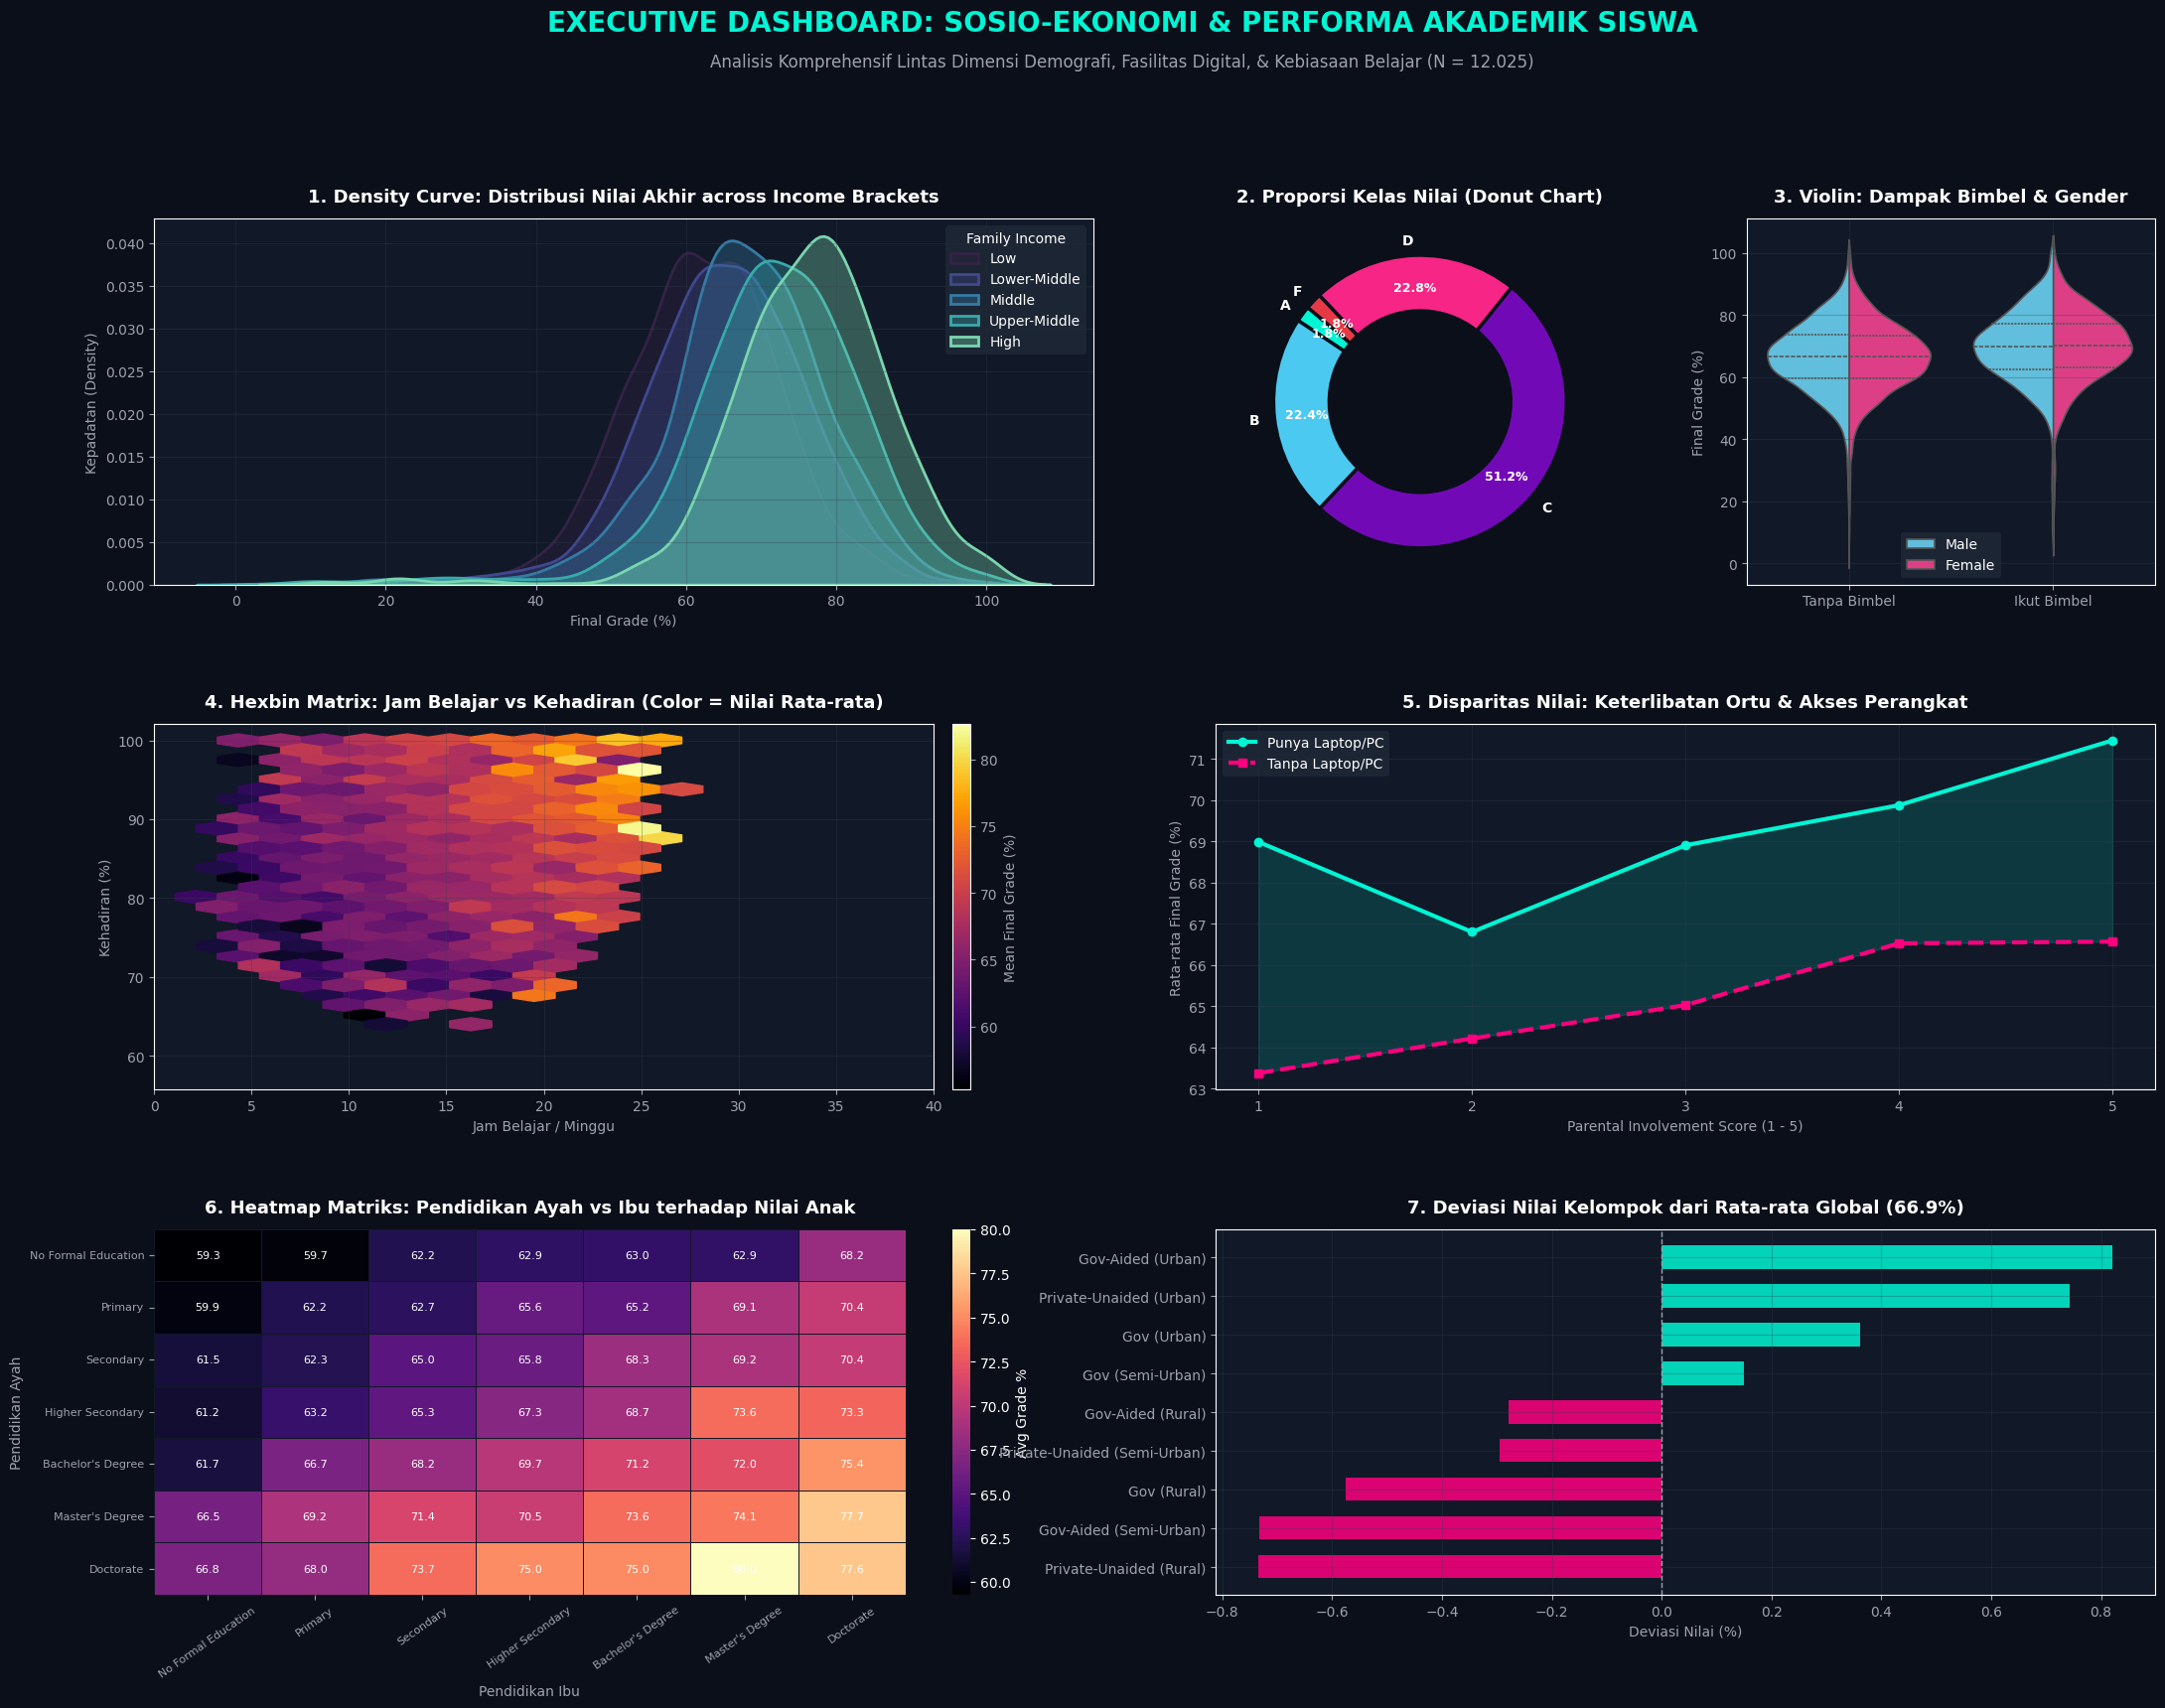

In [1]:
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
import numpy as np
import pandas as pd
import seaborn as sns

# 1. Konfigurasi Tema Dark Luxury
plt.style.use('dark_background')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# 2. Muat Dataset
df = pd.read_csv('student_grade_ses_dataset.csv')

# 3. Canvas GridSpec Mewah (3 Baris x 4 Kolom)
fig = plt.figure(figsize=(26, 18), facecolor='#0b0f19')
gs = GridSpec(3, 4, figure=fig, hspace=0.38, wspace=0.3)

# -------------------------------------------------------------
# Chart 1: Ridgeline / Density Curve across Income Brackets
# -------------------------------------------------------------
ax1 = fig.add_subplot(gs[0, :2])
ax1.set_facecolor('#111827')
income_order = ['Low', 'Lower-Middle', 'Middle', 'Upper-Middle', 'High']
palette_inc = sns.color_palette('mako', n_colors=len(income_order))

for i, inc in enumerate(income_order):
  subset = df[df['family_income_bracket'] == inc]['final_grade_pct']
  sns.kdeplot(
      subset,
      ax=ax1,
      label=inc,
      color=palette_inc[i],
      fill=True,
      alpha=0.35,
      linewidth=2,
  )

ax1.set_title(
    '1. Density Curve: Distribusi Nilai Akhir across Income Brackets',
    fontsize=13,
    fontweight='bold',
    color='white',
    pad=12,
)
ax1.set_xlabel('Final Grade (%)', color='#9ca3af')
ax1.set_ylabel('Kepadatan (Density)', color='#9ca3af')
ax1.legend(
    title='Family Income',
    facecolor='#1f2937',
    edgecolor='none',
    labelcolor='white',
)
ax1.tick_params(colors='#9ca3af')
ax1.grid(color='#374151', alpha=0.3)

# -------------------------------------------------------------
# Chart 2: Neon Donut Chart (Proporsi Grade Class)
# -------------------------------------------------------------
ax2 = fig.add_subplot(gs[0, 2])
ax2.set_facecolor('#111827')
grade_counts = df['grade_class'].value_counts()[['A', 'B', 'C', 'D', 'F']]
colors_grade = ['#00f5d4', '#4cc9f0', '#7209b7', '#f72585', '#e63946']
wedges, texts, autotexts = ax2.pie(
    grade_counts,
    labels=grade_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    pctdistance=0.78,
    colors=colors_grade,
    wedgeprops=dict(width=0.38, edgecolor='#0b0f19', linewidth=2.5),
    textprops=dict(color='white', fontweight='bold'),
)
for at in autotexts:
  at.set_color('#ffffff')
  at.set_fontsize(9)
ax2.set_title(
    '2. Proporsi Kelas Nilai (Donut Chart)',
    fontsize=13,
    fontweight='bold',
    color='white',
    pad=12,
)

# -------------------------------------------------------------
# Chart 3: Split Violin Plot (Dampak Bimbel & Gender)
# -------------------------------------------------------------
ax3 = fig.add_subplot(gs[0, 3])
ax3.set_facecolor('#111827')
df_gender = df[df['gender'].isin(['Male', 'Female'])]
sns.violinplot(
    data=df_gender,
    x='extra_tutoring',
    y='final_grade_pct',
    hue='gender',
    split=True,
    palette={'Male': '#4cc9f0', 'Female': '#f72585'},
    inner='quart',
    ax=ax3,
    linewidth=1.2,
)
ax3.set_title(
    '3. Violin: Dampak Bimbel & Gender',
    fontsize=13,
    fontweight='bold',
    color='white',
    pad=12,
)
ax3.set_xticklabels(['Tanpa Bimbel', 'Ikut Bimbel'], color='white')
ax3.set_xlabel('', color='#9ca3af')
ax3.set_ylabel('Final Grade (%)', color='#9ca3af')
ax3.legend(facecolor='#1f2937', edgecolor='none', labelcolor='white')
ax3.tick_params(colors='#9ca3af')
ax3.grid(color='#374151', alpha=0.3)

# -------------------------------------------------------------
# Chart 4: Hexbin Density Heatmap (Jam Belajar vs Kehadiran vs Nilai)
# -------------------------------------------------------------
ax4 = fig.add_subplot(gs[1, 0:2])
ax4.set_facecolor('#111827')
hb = ax4.hexbin(
    df['study_hours_per_week'],
    df['attendance_rate_pct'],
    C=df['final_grade_pct'],
    gridsize=30,
    cmap='inferno',
    reduce_C_function=np.mean,
    mincnt=5,
)
cb = fig.colorbar(hb, ax=ax4, orientation='vertical', pad=0.02)
cb.set_label('Mean Final Grade (%)', color='#9ca3af', fontsize=10)
cb.ax.yaxis.set_tick_params(color='#9ca3af')
plt.setp(plt.getp(cb.ax.axes, 'yticklabels'), color='#9ca3af')
ax4.set_title(
    '4. Hexbin Matrix: Jam Belajar vs Kehadiran (Color = Nilai Rata-rata)',
    fontsize=13,
    fontweight='bold',
    color='white',
    pad=12,
)
ax4.set_xlabel('Jam Belajar / Minggu', color='#9ca3af')
ax4.set_ylabel('Kehadiran (%)', color='#9ca3af')
ax4.set_xlim(0, 40)
ax4.tick_params(colors='#9ca3af')
ax4.grid(color='#374151', alpha=0.3)

# -------------------------------------------------------------
# Chart 5: Area Disparity Gap (Keterlibatan Ortu & Fasilitas Komputer)
# -------------------------------------------------------------
ax5 = fig.add_subplot(gs[1, 2:])
ax5.set_facecolor('#111827')
piv = df.pivot_table(
    index='parental_involvement_score',
    columns='has_computer_or_laptop',
    values='final_grade_pct',
    aggfunc='mean',
)
ax5.plot(
    piv.index,
    piv[1],
    marker='o',
    linewidth=3,
    color='#00f5d4',
    label='Punya Laptop/PC',
)
ax5.plot(
    piv.index,
    piv[0],
    marker='s',
    linewidth=3,
    color='#ff007f',
    linestyle='--',
    label='Tanpa Laptop/PC',
)
ax5.fill_between(piv.index, piv[1], piv[0], color='#00f5d4', alpha=0.15)
ax5.set_title(
    '5. Disparitas Nilai: Keterlibatan Ortu & Akses Perangkat',
    fontsize=13,
    fontweight='bold',
    color='white',
    pad=12,
)
ax5.set_xlabel('Parental Involvement Score (1 - 5)', color='#9ca3af')
ax5.set_ylabel('Rata-rata Final Grade (%)', color='#9ca3af')
ax5.set_xticks([1, 2, 3, 4, 5])
ax5.legend(facecolor='#1f2937', edgecolor='none', labelcolor='white')
ax5.tick_params(colors='#9ca3af')
ax5.grid(color='#374151', alpha=0.3)

# -------------------------------------------------------------
# Chart 6: Matriks Pendidikan Ayah vs Ibu (Heatmap)
# -------------------------------------------------------------
ax6 = fig.add_subplot(gs[2, 0:2])
ax6.set_facecolor('#111827')
edu_order = [
    'No Formal Education',
    'Primary',
    'Secondary',
    'Higher Secondary',
    "Bachelor's Degree",
    "Master's Degree",
    'Doctorate',
]
edu_pivot = df.pivot_table(
    index='father_education_level',
    columns='mother_education_level',
    values='final_grade_pct',
    aggfunc='mean',
)
edu_order_present = [e for e in edu_order if e in edu_pivot.index]
edu_pivot = edu_pivot.reindex(
    index=edu_order_present, columns=edu_order_present
)
sns.heatmap(
    edu_pivot,
    cmap='magma',
    annot=True,
    fmt='.1f',
    ax=ax6,
    cbar_kws={'label': 'Avg Grade %'},
    linewidths=0.5,
    linecolor='#111827',
    annot_kws={'size': 8, 'color': 'white'},
)
ax6.set_title(
    '6. Heatmap Matriks: Pendidikan Ayah vs Ibu terhadap Nilai Anak',
    fontsize=13,
    fontweight='bold',
    color='white',
    pad=12,
)
ax6.set_xlabel('Pendidikan Ibu', color='#9ca3af')
ax6.set_ylabel('Pendidikan Ayah', color='#9ca3af')
ax6.tick_params(axis='x', rotation=35, colors='#9ca3af', labelsize=8)
ax6.tick_params(axis='y', rotation=0, colors='#9ca3af', labelsize=8)

# -------------------------------------------------------------
# Chart 7: Diverging Bar Chart (Deviasi Nilai Kelompok dari Rata-rata Global)
# -------------------------------------------------------------
ax7 = fig.add_subplot(gs[2, 2:])
ax7.set_facecolor('#111827')
overall_mean = df['final_grade_pct'].mean()
group_means = (
    df.groupby(['school_type', 'residence_type'])['final_grade_pct']
    .mean()
    .reset_index()
)
group_means['label'] = (
    group_means['school_type'].str.replace('Government', 'Gov')
    + ' ('
    + group_means['residence_type']
    + ')'
)
group_means['diff'] = group_means['final_grade_pct'] - overall_mean
group_means = group_means.sort_values(by='diff')

bar_colors = ['#ff007f' if x < 0 else '#00f5d4' for x in group_means['diff']]
bars = ax7.barh(
    group_means['label'],
    group_means['diff'],
    color=bar_colors,
    height=0.6,
    edgecolor='none',
    alpha=0.85,
)
ax7.axvline(0, color='#9ca3af', linestyle='--', linewidth=1)
ax7.set_title(
    f'7. Deviasi Nilai Kelompok dari Rata-rata Global ({overall_mean:.1f}%)',
    fontsize=13,
    fontweight='bold',
    color='white',
    pad=12,
)
ax7.set_xlabel('Deviasi Nilai (%)', color='#9ca3af')
ax7.tick_params(colors='#9ca3af')
ax7.grid(color='#374151', alpha=0.3)

# -------------------------------------------------------------
# Super Header
# -------------------------------------------------------------
fig.text(
    0.5,
    0.985,
    'EXECUTIVE DASHBOARD: SOSIO-EKONOMI & PERFORMA AKADEMIK SISWA',
    ha='center',
    fontsize=20,
    fontweight='bold',
    color='#00f5d4',
)
fig.text(
    0.5,
    0.965,
    'Analisis Komprehensif Lintas Dimensi Demografi, Fasilitas Digital, &'
    ' Kebiasaan Belajar (N = 12.025)',
    ha='center',
    fontsize=12,
    color='#9ca3af',
)

plt.savefig(
    'luxury_student_ses_dashboard.png',
    dpi=220,
    bbox_inches='tight',
    facecolor=fig.get_facecolor(),
)
plt.show()